# EDA: ISIC 2024 Challenge (только train, табличные метаданные)
**Задача:** бинарная классификация — злокачественное (`target=1`) или доброкачественное (`target=0`) поражение кожи по снимку (3D TBP, кропы) и табличным метаданным.

**План:** 1) размер, пропуски, константы, дубликаты; 2) дисбаланс и `Indeterminate`; 3) **train-only признаки и утечки**; 4) пациенты и повторы; 5) источник данных (`attribution`, `tile_type`); 6) демография и локализация с доверительными интервалами; 7) числовые признаки: распределения, univariate AUC, нормализация внутри пациента; 8) выводы.

Изображения здесь не разбираются — EDA по ним в `eda-classification-st.ipynb`.

In [96]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path("../data/raw/task_2024/isic-2024-challenge")
df = pd.read_csv(ROOT / "train-metadata.csv", low_memory=False)
print(df.shape)

def wilson(k, n, z=1.96):
    """95% доверительный интервал Уилсона для доли, в %."""
    p = k / n; d = 1 + z**2 / n; c = p + z**2 / (2 * n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return (c - h) / d * 100, (c + h) / d * 100

def rate_table(col):
    g = df.groupby(col, dropna=False).target.agg(k="sum", n="size")
    g["rate_%"] = g.k / g.n * 100
    g["lo"], g["hi"] = zip(*[wilson(k, n) for k, n in zip(g.k, g.n)])
    return g.sort_values("rate_%")

def auc(x, y):
    """ROC-AUC через ранги (Манна–Уитни); NaN пропускаются, 0.5 = нет сигнала."""
    m = x.notna(); x, y = x[m], y[m]
    n1 = y.sum(); n0 = len(y) - n1
    if n1 == 0 or n0 == 0 or x.nunique() < 2: return np.nan
    return (x.rank()[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

df.head(3)

(401059, 55)


,isic_id,target,patient_id,age_approx,sex,anatom_site_general,clin_size_long_diam_mm,image_type,tbp_tile_type,tbp_lv_A,...,lesion_id,iddx_full,iddx_1,iddx_2,iddx_3,iddx_4,iddx_5,mel_mitotic_index,mel_thick_mm,tbp_lv_dnn_lesion_confidence
0,ISIC_0015670,0,IP_1235828,60.0,male,lower extremity,3.04,TBP tile: close-up,3D: white,20.244422,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,97.517282
1,ISIC_0015845,0,IP_8170065,60.0,male,head/neck,1.10,TBP tile: close-up,3D: white,31.712570,...,IL_6727506,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,3.141455
2,ISIC_0015864,0,IP_6724798,60.0,male,posterior torso,3.40,TBP tile: close-up,3D: XP,22.575830,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.804040


## 1. Пропуски

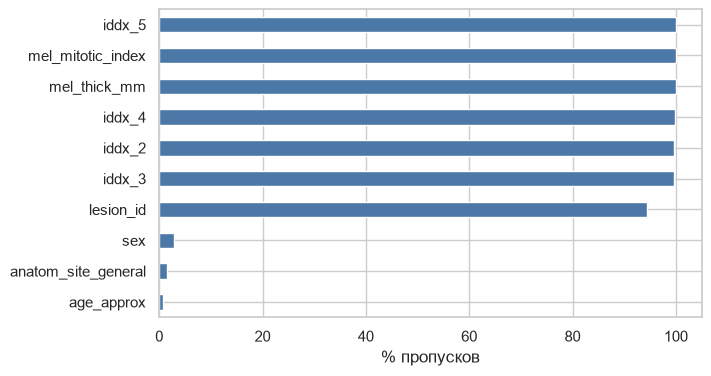

In [97]:
na = (df.isna().mean() * 100).round(2)
na = na[na > 0].sort_values(ascending=False)
ax = na.plot.barh(figsize=(7, 4), color="#4c78a8"); ax.invert_yaxis()
ax.set_xlabel("% пропусков"); plt.show()

Колонки `iddx_*`, `mel_*` заполнены почти только у части (диагностические/гистологические, **есть только в train**) — это **утечка таргета**, в признаки их брать нельзя. `lesion_id` есть у ~5.5% строк. Остальные пропуски (`sex`, `age`, `anatom_site`) малы.

### Пропуски в зависимости от таргета, константы и дубликаты

In [98]:
miss = df.isna().groupby(df.target).mean().T.mul(100).round(2)
miss = miss[(miss > 0).any(axis=1)].rename(columns={0: "benign, % NaN", 1: "malignant, % NaN"})
print(miss.loc[["age_approx", "sex", "anatom_site_general", "lesion_id"]])

const = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("\nконстантные колонки:", const)
print("дубликаты isic_id:", df.isic_id.duplicated().sum(),
      "| полные дубликаты строк (без isic_id):", df.drop(columns="isic_id").duplicated().sum())
print("unique lesion_id:", df.lesion_id.nunique(), "из", df.lesion_id.notna().sum(), "заполненных → каждая lesion_id встречается ровно 1 раз")

target               benign, % NaN  malignant, % NaN
age_approx                    0.70              0.76
sex                           2.87              2.54
anatom_site_general           1.44              0.00
lesion_id                    94.59              0.00

константные колонки: ['image_type']
дубликаты isic_id: 0 | полные дубликаты строк (без isic_id): 0
unique lesion_id: 22058 из 22058 заполненных → каждая lesion_id встречается ровно 1 раз


Пропуски `sex` (2.9%), `age` (0.7%) и `anatom_site_general` (1.4%) практически не зависят от таргета — можно просто импутировать/оставить NaN для GBDT. Исключение — **`anatom_site_general = NaN` (5 756 строк) → 0 malignant**: «неизвестная локализация» бывает только у benign. `image_type` константна (одно значение) — выбросить. Полных дубликатов нет, `isic_id` уникален.

**Важно:** `lesion_id` внутри train не повторяется (22 058 уникальных на 22 058 заполненных), т.е. это не ключ для группировки повторных снимков одной лесии.

## 2. Дисбаланс классов

In [99]:
vc = df.target.value_counts()
print(vc, f"\nдоля malignant: {df.target.mean()*100:.3f}%  (1 к {vc[0]/vc[1]:.0f})")
print(df.iddx_1.value_counts())

target
0    400666
1       393
Name: count, dtype: int64 
доля malignant: 0.098%  (1 к 1020)
iddx_1
Benign           400552
Malignant           393
Indeterminate       114
Name: count, dtype: int64


Крайний дисбаланс: ~0.1% положительных (393 из 401 059).

### Класс `Indeterminate`

In [100]:
print(df.groupby("iddx_1").target.agg(["sum", "size"]))
ind = df[df.iddx_1 == "Indeterminate"]
print("\nIndeterminate по источникам:")
print(ind.attribution.str[:35].value_counts())

               sum    size
iddx_1                    
Benign           0  400552
Indeterminate    0     114
Malignant      393     393

Indeterminate по источникам:
attribution
Frazer Institute, The University of    60
Memorial Sloan Kettering Cancer Cen    39
Department of Dermatology, Hospital    12
University Hospital of Basel            2
Department of Dermatology, Universi     1
Name: count, dtype: int64


114 снимков с диагнозом `Indeterminate` (`iddx_1`) помечены как `target=0` — это скорее «неопределённые», чем доказанно доброкачественные. Их мало (0.03%), но они содержат шум разметки в отрицательном классе: можно оставить как есть, но при анализе ошибок модели их стоит смотреть отдельно (а при чистке — дропнуть). Сконцентрированы в нескольких источниках (Frazer, MSKCC, Hospital Clínic).

## 3. Train-only признаки и утечки таргета

В тестовой части соревнования (по описанию данных Kaggle) отсутствуют `target`, `lesion_id`, `iddx_*`, `mel_*`, `tbp_lv_dnn_lesion_confidence` (а также атрибуция/лицензия). Если признак есть только в train и сильно связан с таргетом — это утечка либо несовместимый признак. Проверим степень связи.

In [101]:
train_only = ["lesion_id", "iddx_full", "iddx_1", "iddx_2", "iddx_3", "iddx_4", "iddx_5",
              "mel_mitotic_index", "mel_thick_mm", "tbp_lv_dnn_lesion_confidence"]
rows = []
for c in train_only:
    nn = df[c].notna()
    rows.append({"feature": c,
                 "% заполнено benign": nn[df.target == 0].mean() * 100,
                 "% заполнено malignant": nn[df.target == 1].mean() * 100,
                 "AUC (по значению)": auc(df[c], df.target) if df[c].dtype != object and str(df[c].dtype) != "str" else np.nan})
leak = pd.DataFrame(rows).set_index("feature").round(3)
leak

,% заполнено benign,% заполнено malignant,AUC (по значению)
feature,,,
lesion_id,5.407,100.000,NaN
iddx_full,100.000,100.000,NaN
iddx_1,100.000,100.000,NaN
iddx_2,0.168,100.000,NaN
iddx_3,0.168,100.000,NaN
iddx_4,0.077,61.578,NaN
iddx_5,0.000,0.000,NaN
mel_mitotic_index,0.000,13.486,NaN
mel_thick_mm,0.000,16.031,NaN


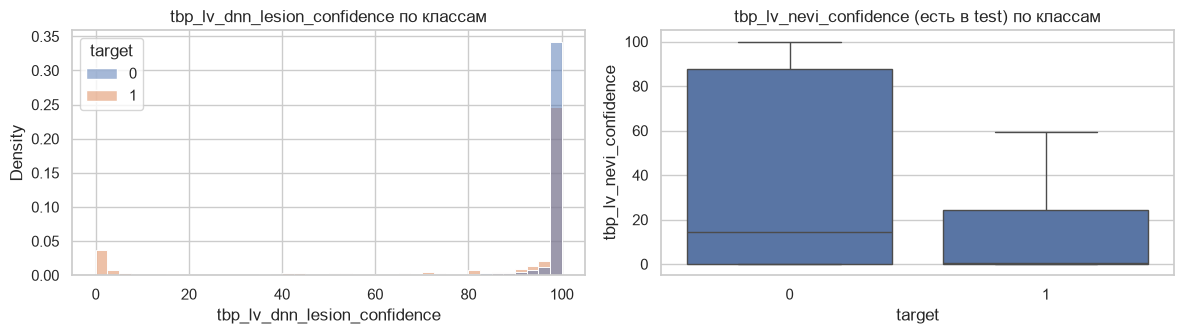

AUC dnn_lesion_confidence: 0.313
AUC nevi_confidence      : 0.354


In [102]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(data=df, x="tbp_lv_dnn_lesion_confidence", hue="target", stat="density", common_norm=False,
             bins=40, ax=ax[0]); ax[0].set_title("tbp_lv_dnn_lesion_confidence по классам")
sns.boxplot(data=df, x="target", y="tbp_lv_nevi_confidence", showfliers=False, ax=ax[1])
ax[1].set_title("tbp_lv_nevi_confidence (есть в test) по классам")
plt.tight_layout(); plt.show()
print("AUC dnn_lesion_confidence:", round(auc(df.tbp_lv_dnn_lesion_confidence, df.target), 3))
print("AUC nevi_confidence      :", round(auc(df.tbp_lv_nevi_confidence, df.target), 3))

**Выводы по утечкам:**
- **`lesion_id` — сильнейшая утечка:** заполнен у **100% malignant** и лишь у 5.4% benign (лесии, за которыми наблюдали). Его наличие — почти идеальный предиктор; в тесте его нет → исключить, не создавать признак «lesion_id notna».
- `iddx_full`/`iddx_1` — **это сам таргет** (`iddx_1 == "Malignant"` ⇔ `target=1`), заполнены у 100%. `iddx_2/3` заполнены у 100% malignant и 0.17% benign, `iddx_4` — у 62% malignant; `mel_*` — только у ~13–16% malignant (`iddx_5` пуст). Всё исключить.
- **`tbp_lv_dnn_lesion_confidence`** — выход внутренней нейросети TBP, обученной на этих же данных. Только в train, сильно разделяет классы (AUC ≈ 0.31, т.е. 0.69 инвертированно). Использовать в качестве признака нельзя; можно лишь как ориентир «потолка» или для анализа ошибок.
- Рядом легитимный аналог — `tbp_lv_nevi_confidence` (есть в test): у malignant заметно ниже (AUC ≈ 0.35).

## 4. Пациенты и повторы

пациентов: 1042 | снимков на пациента: медиана 241.5 макс 9184
пациентов с ≥1 malignant: 259


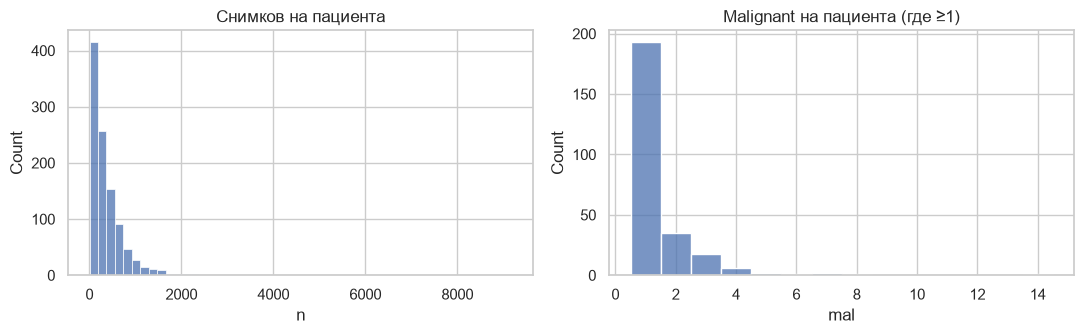

In [103]:
per = df.groupby("patient_id").agg(n=("isic_id", "size"), mal=("target", "sum"))
print("пациентов:", len(per), "| снимков на пациента: медиана", per.n.median(), "макс", per.n.max())
print("пациентов с ≥1 malignant:", (per.mal > 0).sum())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(per.n, bins=50, ax=ax[0]); ax[0].set_title("Снимков на пациента")
sns.histplot(per.mal[per.mal > 0], discrete=True, ax=ax[1]); ax[1].set_title("Malignant на пациента (где ≥1)")
plt.tight_layout(); plt.show()

### Malignant по пациентам

In [104]:
per = df.groupby("patient_id").agg(n=("isic_id", "size"), mal=("target", "sum"))
pm = per[per.mal > 0]
print(f"пациентов с ≥1 malignant: {len(pm)} из {len(per)} ({len(pm)/len(per)*100:.1f}%)")
print("malignant на пациента (среди таких): медиана", pm.mal.median(), "| макс", pm.mal.max())
print("доля malignant внутри пациента с ≥1:", f"{pm.mal.sum()/pm.n.sum()*100:.3f}%")
print("корреляция (Spearman) n_снимков ↔ n_malignant:", round(per.n.rank().corr(per.mal.rank()), 3))
print("пациент → источников:", df.groupby("patient_id").attribution.nunique().max(), "(пациент всегда в одном источнике)")

пациентов с ≥1 malignant: 259 из 1042 (24.9%)
malignant на пациента (среди таких): медиана 1.0 | макс 14
доля malignant внутри пациента с ≥1: 0.252%
корреляция (Spearman) n_снимков ↔ n_malignant: 0.315
пациент → источников: 1 (пациент всегда в одном источнике)


Три четверти пациентов (75%) не имеют ни одного malignant. Больше половины пациентов с malignant имеют ровно 1 случай, максимум — 14. Количество снимков слабо связано с числом malignant — размер «картотеки» пациента не должен быть признаком. Каждый пациент принадлежит ровно одному источнику → при группировке по пациентам источник также разделяется целиком, это нужно учитывать при CV.

## 5. Источник данных (`attribution`) и тип тайла (`tbp_tile_type`)

,k,n,rate_%,lo,hi,patients
site,,,,,,
Basel,13,65218,0.020,0.012,0.034,230
Derm. Hospital Clínic,78,113700,0.069,0.055,0.086,179
ViDIR,14,12640,0.111,0.066,0.186,15
ACEMID MIA,33,28665,0.115,0.082,0.162,44
MSKCC,174,129068,0.135,0.116,0.156,398
Frazer,81,51768,0.156,0.126,0.194,176


tbp_tile_type,3D: XP,3D: white
site,,
ACEMID MIA,1.00,0.00
Basel,0.99,0.01
Derm. Hospital Clínic,1.00,0.00
Frazer,1.00,0.00
MSKCC,0.11,0.89
ViDIR,1.00,0.00


,k,n,rate_%,lo,hi
tbp_tile_type,,,,,
3D: XP,197,285903,0.069,0.060,0.079
3D: white,196,115156,0.170,0.148,0.196


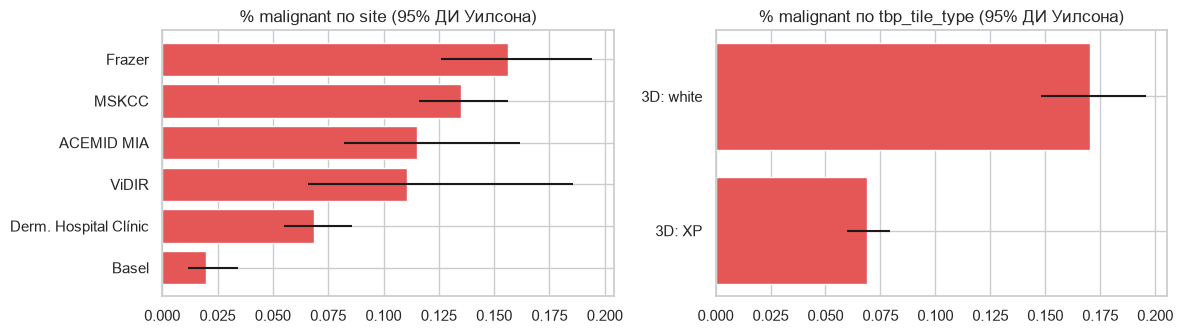

In [105]:
df["site"] = df.attribution.str.split(",").str[0].str.replace("Department of Dermatology", "Derm. Hospital Clínic") \
    .str.replace("Memorial Sloan Kettering Cancer Center", "MSKCC").str.replace("University Hospital of Basel", "Basel") \
    .str.replace("Frazer Institute", "Frazer").str.replace("ViDIR Group", "ViDIR")
t = rate_table("site"); t["patients"] = df.groupby("site").patient_id.nunique()
display(t.round(3))
display(pd.crosstab(df.site, df.tbp_tile_type, normalize="index").round(2))
display(rate_table("tbp_tile_type").round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, col in zip(ax, ["site", "tbp_tile_type"]):
    r = rate_table(col)
    a.barh(r.index.astype(str), r["rate_%"], xerr=[r["rate_%"] - r.lo, r.hi - r["rate_%"]], color="#e45756")
    a.set_title(f"% malignant по {col} (95% ДИ Уилсона)")
plt.tight_layout(); plt.show()

**Источник — один из главных конфаундеров.** Доля malignant отличается почти в 8 раз: 2.0 ‰ в Basel (13 из 65 218) против 15.6 ‰ во Frazer и 13.5 ‰ в MSKCC; доверительные интервалы не пересекаются. `tbp_tile_type = 3D: white` (в основном MSKCC, 89% его снимков) даёт 0.17% против 0.069% у `3D: XP`. Разные источники имеют разную аппаратуру и разное распределение пациентов, поэтому:
- модель может выучить «центр», а не патологию → на тесте (с другими/теми же центрами) качество будет отличаться;
- валидацию стоит делать группами пациентов, а для оценки обобщения — дополнительно leave-one-site-out;
- `attribution` в тесте нет, но `tbp_tile_type` есть — признак-прокси центра.

## 6. Демография и локализация

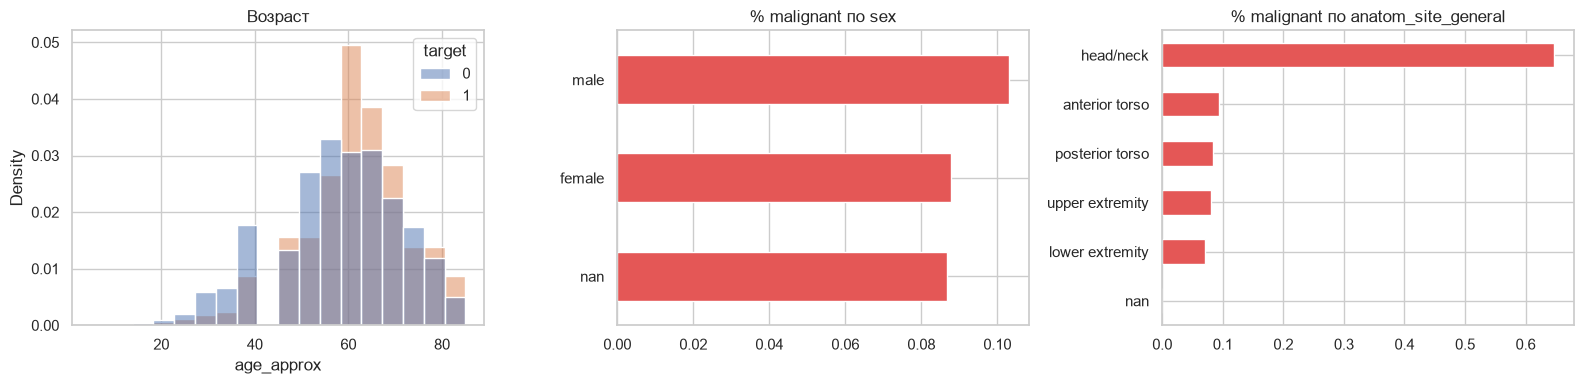

In [106]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x="age_approx", hue="target", stat="density", common_norm=False, bins=18, ax=ax[0]); ax[0].set_title("Возраст")
for a, col in zip(ax[1:], ["sex", "anatom_site_general"]):
    r = df.groupby(col, dropna=False).target.mean().mul(100).sort_values()
    r.plot.barh(ax=a, color="#e45756"); a.set_title(f"% malignant по {col}"); a.set_ylabel("")
plt.tight_layout(); plt.show()

Доля malignant растёт с возрастом до ~50–70 лет (0.04% → 0.12%); резко выделяется голова/шея (0.65% против 0.07–0.09% на остальных зонах). Разница по полу (0.103% vs 0.088%) в пределах шума — см. доверительные интервалы в разделе 6. Сигналы полезные, но слабые.

**Доверительные интервалы по демографии и локализации** (малое число положительных → оценки шумные):

In [107]:
for col in ["sex", "anatom_site_general", "tbp_lv_location_simple"]:
    print(f"\n== {col}")
    display(rate_table(col).round(3))
age = df.assign(age_bin=pd.cut(df.age_approx, [0, 30, 40, 50, 60, 70, 80, 90]))
display(rate_table_age := age.groupby("age_bin", observed=True).target.agg(k="sum", n="size")
        .assign(rate=lambda g: (g.k / g.n * 100).round(3)))
print("средний возраст: benign", round(df[df.target==0].age_approx.mean(), 1),
      "| malignant", round(df[df.target==1].age_approx.mean(), 1))


== sex


,k,n,rate_%,lo,hi
sex,,,,,
NaN,10,11517,0.087,0.047,0.160
female,109,123996,0.088,0.073,0.106
male,274,265546,0.103,0.092,0.116



== anatom_site_general


,k,n,rate_%,lo,hi
anatom_site_general,,,,,
NaN,0,5756,0.000,0.000,0.067
lower extremity,73,103028,0.071,0.056,0.089
upper extremity,57,70557,0.081,0.062,0.105
posterior torso,103,121902,0.084,0.070,0.102
anterior torso,82,87770,0.093,0.075,0.116
head/neck,78,12046,0.648,0.519,0.807



== tbp_lv_location_simple


,k,n,rate_%,lo,hi
tbp_lv_location_simple,,,,,
Unknown,0,5756,0.000,0.000,0.067
Right Leg,29,49953,0.058,0.040,0.083
Right Arm,23,34209,0.067,0.045,0.101
Left Leg,44,53075,0.083,0.062,0.111
Torso Back,103,121902,0.084,0.070,0.102
Torso Front,82,87770,0.093,0.075,0.116
Left Arm,34,36348,0.094,0.067,0.131
Head & Neck,78,12046,0.648,0.519,0.807


,k,n,rate
age_bin,,,
"(0, 30]",6,16220,0.037
"(30, 40]",19,42840,0.044
"(40, 50]",54,71504,0.076
"(50, 60]",132,112232,0.118
"(60, 70]",116,94721,0.122
"(70, 80]",48,51897,0.092
"(80, 90]",15,8847,0.170


средний возраст: benign 58.0 | malignant 61.4


- **Пол:** 0.103% (м) vs 0.088% (ж), ДИ [0.092–0.116] и [0.073–0.106] сильно пересекаются → различие статистически слабое, признак `sex` почти не несёт сигнала.
- **Голова/шея:** 0.65% [0.52–0.81] против 0.06–0.09% — ДИ не пересекаются, самый надёжный категориальный сигнал. Среди остальных зон разница (ноги ~0.06–0.08% против туловища/рук ~0.09%) невелика.
- **Возраст:** malignant старше в среднем на ~3.4 года (61.4 vs 58.0); доля растёт с 0.04% (<40) до ~0.12% (50–70), в 70–80 снижается до 0.09%, а в 80+ 0.17% (всего 15 случаев, оценка шумная) → зависимость нелинейна.

## 7. Числовые признаки TBP

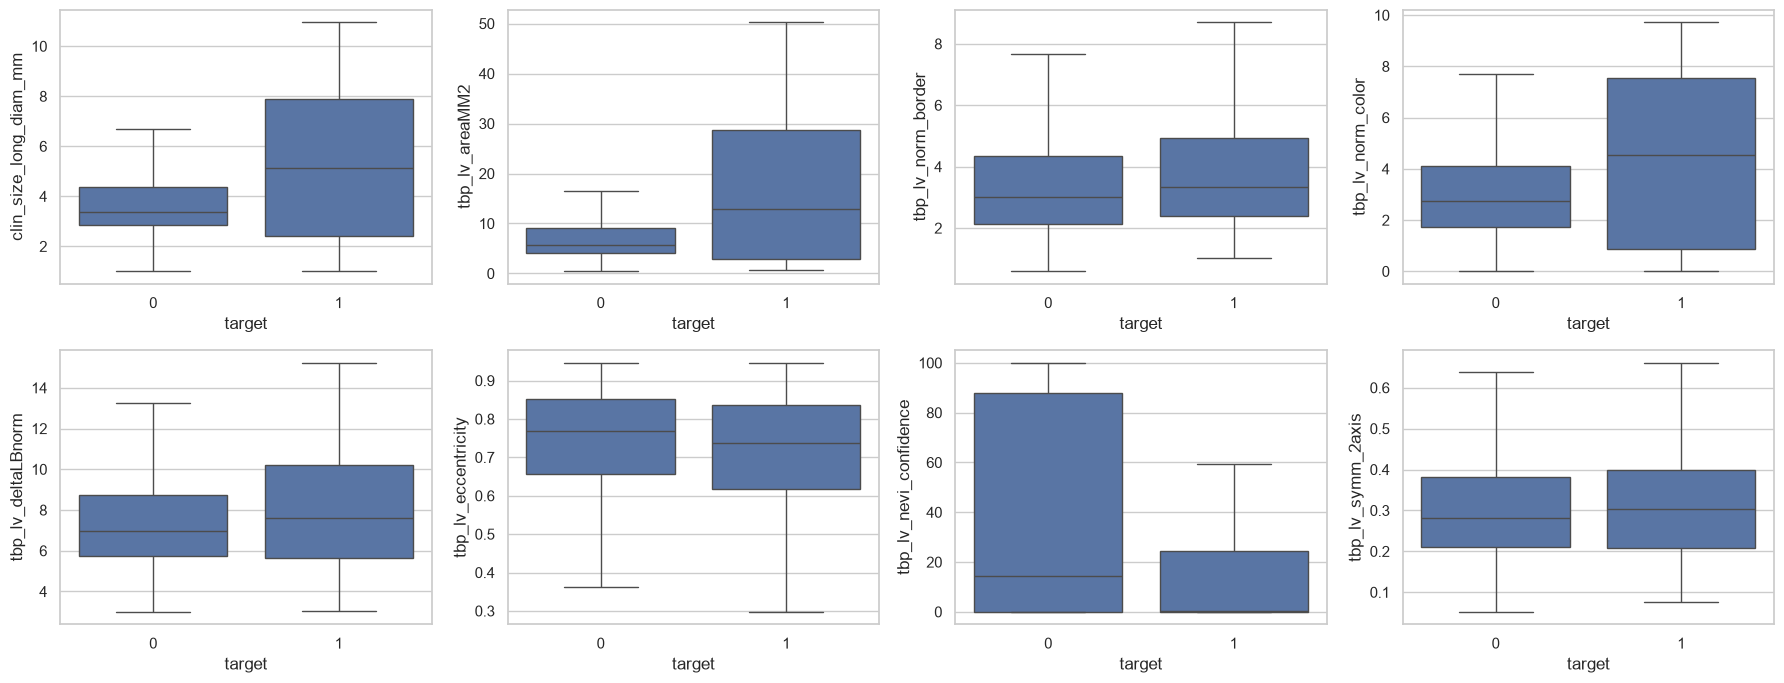

In [108]:
feats = ["clin_size_long_diam_mm", "tbp_lv_areaMM2", "tbp_lv_norm_border", "tbp_lv_norm_color",
         "tbp_lv_deltaLBnorm", "tbp_lv_eccentricity", "tbp_lv_nevi_confidence", "tbp_lv_symm_2axis"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for a, f in zip(axes.ravel(), feats):
    s = df[[f, "target"]].copy(); s[f] = s[f].clip(upper=s[f].quantile(0.99))
    sns.boxplot(data=s, x="target", y=f, ax=a, showfliers=False)
plt.tight_layout(); plt.show()

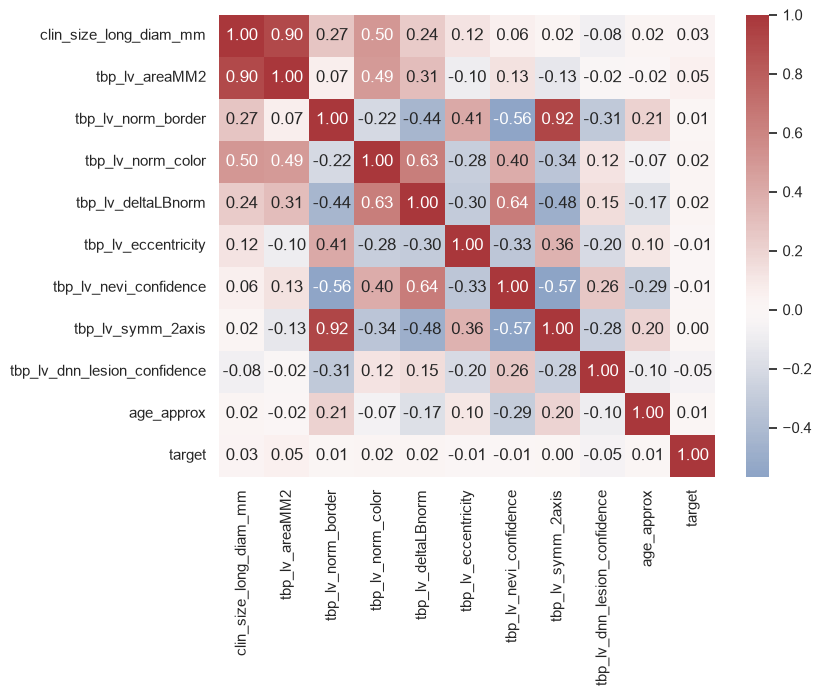

In [109]:
corr = df[feats + ["tbp_lv_dnn_lesion_confidence", "age_approx", "target"]].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0); plt.show()

**Размер и цвет.** Злокачественные родинки в среднем крупнее (медиана 5.1 мм против 3.4 мм). Простая связь любого признака с ответом очень слабая (корреляция меньше 0.04), а многие размерные признаки дублируют друг друга.

### Как распределены признаки

,min,median,max,skew,% >99q
tbp_lv_areaMM2,0.43,5.69,334.15,5.91,1.0
tbp_lv_perimeterMM,2.58,10.02,102.49,3.12,1.0
clin_size_long_diam_mm,1.00,3.37,28.40,2.83,1.0
tbp_lv_stdLExt,0.64,2.15,25.53,2.82,1.0
tbp_lv_minorAxisMM,0.27,2.27,18.39,2.43,1.0
tbp_lv_area_perim_ratio,10.76,17.42,87.21,1.98,1.0
tbp_lv_deltaA,-13.82,4.64,32.14,1.81,1.0
tbp_lv_radial_color_std_max,0.00,0.90,11.49,1.75,1.0
tbp_lv_stdL,0.27,2.19,17.56,1.58,1.0
tbp_lv_color_std_mean,0.00,0.93,9.95,1.57,1.0


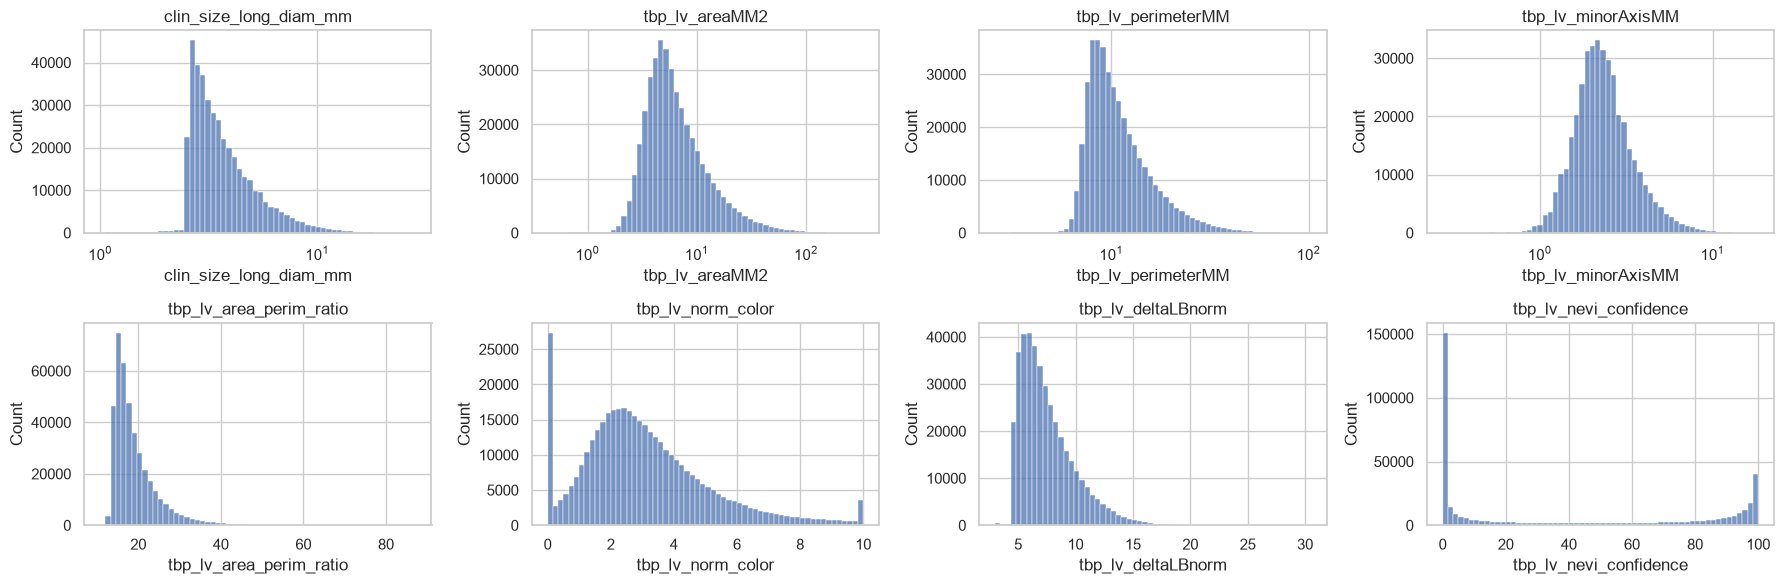

In [110]:
num = [c for c in df.select_dtypes("number").columns if c not in ("target", "tbp_lv_dnn_lesion_confidence", "mel_thick_mm")]
desc = df[num].agg(["min", "median", "max", "skew"]).T
desc["% >99q"] = [(df[c] > df[c].quantile(.99)).mean() * 100 for c in num]
display(desc.sort_values("skew", ascending=False).head(10).round(2))

fig, ax = plt.subplots(2, 4, figsize=(18, 6))
for a, f in zip(ax.ravel(), ["clin_size_long_diam_mm", "tbp_lv_areaMM2", "tbp_lv_perimeterMM", "tbp_lv_minorAxisMM",
                              "tbp_lv_area_perim_ratio", "tbp_lv_norm_color", "tbp_lv_deltaLBnorm", "tbp_lv_nevi_confidence"]):
    sns.histplot(df[f].dropna(), bins=60, ax=a, log_scale=(f in ("tbp_lv_areaMM2", "tbp_lv_perimeterMM", "clin_size_long_diam_mm", "tbp_lv_minorAxisMM")))
    a.set_title(f)
plt.tight_layout(); plt.show()

Размеры перекошены: мелких родинок много, крупных мало (площадь до 334 мм² при типичных ~6).

### Какие признаки лучше всего разделяют классы
Для каждого признака считаем AUC: 0.5 — признак бесполезен, чем дальше от 0.5 (вверх или вниз), тем лучше он разделяет классы.

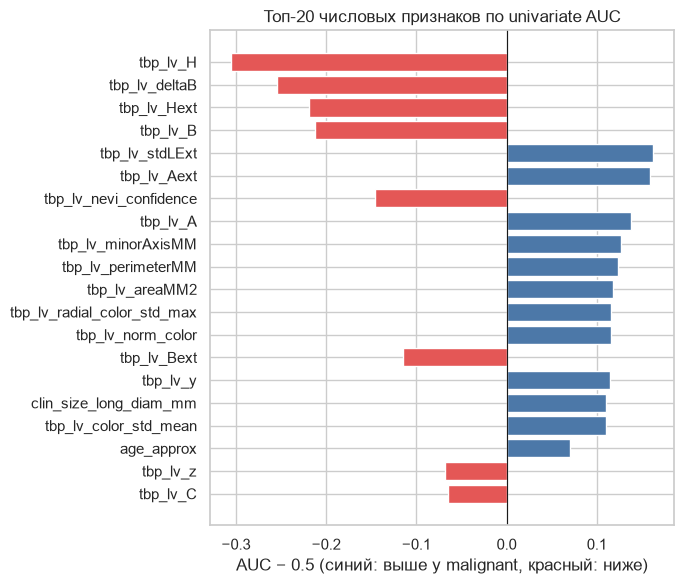

tbp_lv_H                       0.195
tbp_lv_deltaB                  0.246
tbp_lv_Hext                    0.280
tbp_lv_B                       0.288
tbp_lv_stdLExt                 0.662
tbp_lv_Aext                    0.659
tbp_lv_nevi_confidence         0.354
tbp_lv_A                       0.638
tbp_lv_minorAxisMM             0.627
tbp_lv_perimeterMM             0.623
tbp_lv_areaMM2                 0.618
tbp_lv_radial_color_std_max    0.616
dtype: float64

In [111]:
feat_num = [c for c in df.select_dtypes("number").columns if c not in ("target", "tbp_lv_dnn_lesion_confidence", "mel_thick_mm")]
a = pd.Series({c: auc(df[c], df.target) for c in feat_num}).dropna()
a = a.loc[(a - 0.5).abs().sort_values(ascending=False).index]
top = a.head(20)
plt.figure(figsize=(7, 6))
plt.barh(top.index[::-1], (top - 0.5)[::-1], color=np.where(top[::-1] > 0.5, "#4c78a8", "#e45756"))
plt.axvline(0, color="k", lw=.8); plt.xlabel("AUC − 0.5 (синий: выше у malignant, красный: ниже)")
plt.title("Топ-20 числовых признаков по univariate AUC"); plt.tight_layout(); plt.show()
a.round(3).head(12)

Сильнее всего различают классы цветовые признаки: `tbp_lv_H`, `deltaB`, `Hext`, `B`. У злокачественных они ниже (поэтому AUC меньше 0.5). Это настоящий сигнал: он есть в каждой больнице. Дальше идут другие цветовые признаки и размер родинки (AUC около 0.62–0.66). Сильных признаков много, и они похожи друг на друга.

## 8. Выводы
**Что за данные**
- 401 059 снимков от 1 042 пациентов. Злокачественных всего 393 (0.1%), то есть примерно 1 на 1000. Поэтому модели надо специально «подсказывать», что редкий класс важен, а качество мерить не долей верных ответов, а метриками для редких событий (PR-AUC, pAUC).
- У 75% пациентов нет ни одного злокачественного снимка.
- 114 снимков с диагнозом «неопределённый» записаны как доброкачественные — это возможные ошибки разметки.
- Пропусков мало, дубликатов нет. Колонка `image_type` везде одинаковая — её можно удалить.

**Что нельзя использовать как признаки (подсказки о ответе)**
- `lesion_id`: он есть у всех злокачественных и лишь у 5% доброкачественных. Модель просто угадывала бы по тому, заполнено поле или нет.
- `iddx_*` и `mel_*`: это сам диагноз и результаты гистологии. `iddx_1` буквально повторяет ответ.
- `tbp_lv_dnn_lesion_confidence`: оценка другой нейросети, обученной на этих же данных. В тесте её не будет.
- Все эти колонки в тестовых данных соревнования отсутствуют.

**Какие признаки полезны**
- Лучше всего различают классы цветовые характеристики родинки (`tbp_lv_H`, `deltaB`, `B`). Это настоящий сигнал, он держится в каждой больнице. Дальше идут размер и цвет границы.
- Каждый признак по отдельности даёт лишь умеренный сигнал.
- Размеры сильно перекошены (много мелких, мало огромных).
- Полезно сравнивать родинку с остальными родинками **того же человека**: так заметнее, какая из них «выбивается». Для `deltaLBnorm` это заметно улучшает результат.
- Возраст: риск растёт до 50–70 лет. Локализация: на голове и шее злокачественных в 7–8 раз больше, чем на других участках. Пол почти ничего не даёт — разница на уровне случайности.